# Лабораторна 2. Токенізатори

Я реалізував послівний токенізатор, символьні n-грами, BPE та WordPiece. Порівнюю їх на FLORES dev: по 997 речень англійською, українською й грузинською. Усі обчислення виконуються на CPU.

Завдання: [lpnu-llm/lab-tokenizer](https://github.com/lpnu-llm/lab-tokenizer). Для запуску потрібні пакети з `requirements.txt`.

## 1. Послівний токенізатор

Я переводжу текст у нижній регістр і відділяю слова, числа та знаки. Апостроф усередині слова зберігається, пробіли й початковий регістр - ні.

In [1]:
from collections import defaultdict
from functools import lru_cache
import re
from collections import Counter


def word_tokenize(text):
    return re.findall("[^\\W\\d_]+(?:['’ʼ][^\\W\\d_]+)*|\\d+|[^\\w\\s]|_", text.lower())


def test_word_tokenize():
    assert word_tokenize("Модель читає текст.") == ["модель", "читає", "текст", "."]
    assert word_tokenize("Комп'ютер і пам’ять") == ["комп'ютер", "і", "пам’ять"]
    assert word_tokenize("GPT-2: 50 токенів!") == [
        "gpt",
        "-",
        "2",
        ":",
        "50",
        "токенів",
        "!",
    ]
    assert word_tokenize("") == []


test_word_tokenize()
print("✓ word_tokenize")

✓ word_tokenize


### Словник та OOV

Я призначаю токенам ID: `<pad>` = 0, `<unk>` = 1, решта - від 2. Невідомі слова отримують однаковий `<unk>`. Послівний метод простий, але різні словоформи збільшують словник.

In [2]:
def build_word_vocab(texts):
    tokens = sorted({token for text in texts for token in word_tokenize(text)})
    return {"<pad>": 0, "<unk>": 1, **{token: i for i, token in enumerate(tokens, 2)}}


def encode_words(text, vocab):
    return [vocab.get(token, vocab["<unk>"]) for token in word_tokenize(text)]


def test_word_vocab():
    vocab = build_word_vocab(["Кіт спить.", "Пес спить."])
    assert vocab["<pad>"] == 0
    assert vocab["<unk>"] == 1
    assert encode_words("Кіт біжить.", vocab) == [vocab["кіт"], 1, vocab["."]]
    assert encode_words("Хом'як біжить.", vocab)[0:2] == [1, 1]


test_word_vocab()
print("✓ word vocabulary")

✓ word vocabulary


## 2. Символьні n-грами

`n` - кількість символів у фрагменті. Для `кіт`, `n=3` отримую `^кі`, `кіт`, `іт$`. Якщо рядок із межами коротший за `n`, доповнюю його символом `~`: для `n=6` маю `^кіт$~`.

Жаккар - `|A ∩ B| / |A ∪ B|`. Після переходу до множин порядок і повторення не враховуються. Для двох порожніх множин повертаю 1 за умовою шаблону.

In [3]:
def char_ngrams(word, n=3):
    if type(n) is not int or n <= 0:
        raise ValueError("n має бути додатним цілим числом")
    if not word:
        return []
    bounded = ("^" + word + "$").ljust(n, "~")
    return [bounded[i : i + n] for i in range(len(bounded) - n + 1)]


def ngram_overlap(word_a, word_b, n=3):
    a, b = (set(char_ngrams(word_a, n)), set(char_ngrams(word_b, n)))
    return len(a & b) / len(a | b) if a | b else 1.0


def test_ngrams():
    assert char_ngrams("кіт", 3) == ["^кі", "кіт", "іт$"]
    assert char_ngrams("кіт", 2) == ["^к", "кі", "іт", "т$"]
    assert char_ngrams("", 3) == []
    assert char_ngrams("кіт", 6) == ["^кіт$~"]
    assert char_ngrams("кіт", 7) == ["^кіт$~~"]
    assert ngram_overlap("кіт", "пес", 6) == 0.0
    assert ngram_overlap("токенізатор", "токенізація", 3) > 0.4
    assert ngram_overlap("кіт", "трактор", 3) == 0.0
    try:
        char_ngrams("слово", 0)
    except ValueError:
        pass
    else:
        raise AssertionError("n має бути додатним")


test_ngrams()
print("✓ character n-grams")

✓ character n-grams


### Словник n-грам

Я збираю відомі фрагменти навчального корпусу й призначаю ID. Невідомі n-грами нового тексту замінюю на `<unk>`. Для навчання та застосування використовую однакове `n` і padding.

In [4]:
def build_ngram_vocab(texts, n=3):
    grams = set()
    for text in texts:
        for word in word_tokenize(text):
            grams.update(char_ngrams(word, n))
    vocab = {"<pad>": 0, "<unk>": 1}
    for gram in sorted(grams):
        vocab[gram] = len(vocab)
    return vocab


def encode_ngrams(text, vocab, n=3):
    return [
        vocab.get(gram, vocab["<unk>"])
        for word in word_tokenize(text)
        for gram in char_ngrams(word, n)
    ]


def test_ngram_vocab():
    vocab = build_ngram_vocab(["кіт"], 3)
    assert len(encode_ngrams("кіт", vocab)) == 3
    assert 1 not in encode_ngrams("кіт", vocab)
    assert 1 in encode_ngrams("cat", vocab)
    assert vocab["<pad>"] == 0 and vocab["<unk>"] == 1


test_ngram_vocab()
print("✓ n-gram vocabulary")

✓ n-gram vocabulary


## 3. BPE

Я починаю із символів та `</w>`, потім зливаю найчастішу сусідню пару. Частоти враховують повтори слів; при нічиїй беру пару за абеткою. Допоміжні функції оновлюють лише слова з вибраною парою. `apply_bpe` відтворює збережений порядок злиттів.

In [5]:
def word_frequencies(texts):
    return Counter(
        (
            token
            for text in texts
            for token in word_tokenize(text)
            if token.replace("'", "").replace("’", "").replace("ʼ", "").isalpha()
        )
    )


def most_frequent_pair(vocabulary):
    counts = Counter()
    for symbols, frequency in vocabulary.items():
        for pair in zip(symbols, symbols[1:]):
            counts[pair] += frequency
    return min(counts, key=lambda pair: (-counts[pair], pair)) if counts else None


def merge_pair(symbols, pair):
    merged, i = ([], 0)
    while i < len(symbols):
        if i + 1 < len(symbols) and (symbols[i], symbols[i + 1]) == pair:
            merged.append(symbols[i] + symbols[i + 1])
            i += 2
        else:
            merged.append(symbols[i])
            i += 1
    return tuple(merged)


def _training_counts(vocabulary):
    words = list(vocabulary)
    counts = list(vocabulary.values())
    pair_counts = Counter()
    pair_words = defaultdict(set)
    symbol_counts = Counter()
    for index, symbols in enumerate(words):
        count = counts[index]
        for symbol in symbols:
            symbol_counts[symbol] += count
        for pair in zip(symbols, symbols[1:]):
            pair_counts[pair] += count
            pair_words[pair].add(index)
    return (words, counts, pair_counts, pair_words, symbol_counts)


def _merge_training_pair(state, pair, merge):
    words, counts, pair_counts, pair_words, symbol_counts = state
    for index in list(pair_words[pair]):
        old = words[index]
        new = merge(old, pair)
        count = counts[index]
        for symbol, amount in Counter(old).items():
            symbol_counts[symbol] -= amount * count
        for symbol, amount in Counter(new).items():
            symbol_counts[symbol] += amount * count
        for old_pair, amount in Counter(zip(old, old[1:])).items():
            pair_counts[old_pair] -= amount * count
            pair_words[old_pair].discard(index)
            if pair_counts[old_pair] == 0:
                del pair_counts[old_pair]
        for new_pair, amount in Counter(zip(new, new[1:])).items():
            pair_counts[new_pair] += amount * count
            pair_words[new_pair].add(index)
        words[index] = new


def train_bpe(texts, num_merges):
    if type(num_merges) is not int or num_merges < 0:
        raise ValueError("кількість злиттів має бути невід’ємним цілим числом")
    vocabulary = {}
    for word, count in word_frequencies(texts).items():
        vocabulary[tuple(word) + ("</w>",)] = count
    state = _training_counts(vocabulary)
    pair_counts = state[2]
    merges = []
    for _ in range(num_merges):
        if not pair_counts:
            break
        pair = min(pair_counts, key=lambda p: (-pair_counts[p], p))
        _merge_training_pair(state, pair, merge_pair)
        merges.append(pair)
    return merges


def apply_bpe(word, merges):
    if not word:
        return []
    symbols = tuple(word) + ("</w>",)
    for pair in merges:
        symbols = merge_pair(symbols, pair)
    return list(symbols)


def test_bpe():
    vocabulary = {("м", "а", "м", "а", "</w>"): 2, ("м", "а", "л", "а", "</w>"): 1}
    assert most_frequent_pair(vocabulary) == ("м", "а")
    assert merge_pair(("м", "а", "м", "а", "</w>"), ("м", "а")) == ("ма", "ма", "</w>")
    merges = train_bpe(["мама мама мала тон"], 3)
    assert merges[0] == ("м", "а")
    assert apply_bpe("мама", merges) == ["мама</w>"]
    unseen = apply_bpe("мамонт", merges)
    assert "<unk>" not in unseen
    assert "".join(unseen).replace("</w>", "") == "мамонт"


test_bpe()
print("✓ BPE")

✓ BPE


### Середня довжина BPE

Я ділю суму `частота слова × кількість його токенів` на кількість слів. Тут враховую лише літерні слова; у великій таблиці fertility токенізується весь текст.

In [6]:
def average_bpe_length(texts, merges):
    frequencies = word_frequencies(texts)
    total_words = sum(frequencies.values())
    if not total_words:
        raise ValueError("Корпус без слів")
    return (
        sum(
            (
                count * len(apply_bpe(word, merges))
                for word, count in frequencies.items()
            )
        )
        / total_words
    )


def test_average_bpe_length():
    corpus = ["токен токени токенізація", "токенізатор токенізує текст"]
    merges = train_bpe(corpus, 20)
    before = average_bpe_length(corpus, [])
    after = average_bpe_length(corpus, merges)
    assert after < before
    assert before > 1


test_average_bpe_length()
print("✓ BPE reduces average sequence length")

✓ BPE reduces average sequence length


## 4. WordPiece

Я вибираю пару за `score(a,b) = freq(a,b) / (freq(a) × freq(b))`. Тому рідкісна пара може випередити часту. `##` позначає продовження слова.

При застосуванні шукаю найдовший доступний фрагмент. Якщо решта не розбирається, повертаю `[UNK]` для всього слова. Це навчальна схема WordPiece з умови.

In [7]:
def wordpiece_symbols(word):
    return tuple(
        (character if i == 0 else "##" + character for i, character in enumerate(word))
    )


def wordpiece_pair_scores(vocabulary):
    token_counts, pair_counts = (Counter(), Counter())
    for symbols, count in vocabulary.items():
        for symbol in symbols:
            token_counts[symbol] += count
        for pair in zip(symbols, symbols[1:]):
            pair_counts[pair] += count
    return {
        pair: count / (token_counts[pair[0]] * token_counts[pair[1]])
        for pair, count in pair_counts.items()
    }


def merge_wordpiece_pair(symbols, pair):
    merged, i = ([], 0)
    while i < len(symbols):
        if i + 1 < len(symbols) and (symbols[i], symbols[i + 1]) == pair:
            right = (
                symbols[i + 1][2:]
                if symbols[i + 1].startswith("##")
                else symbols[i + 1]
            )
            merged.append(symbols[i] + right)
            i += 2
        else:
            merged.append(symbols[i])
            i += 1
    return tuple(merged)


def train_wordpiece(texts, vocab_size):
    if type(vocab_size) is not int or vocab_size <= 0:
        raise ValueError("розмір словника має бути додатним цілим числом")
    vocabulary = {
        wordpiece_symbols(word): count
        for word, count in word_frequencies(texts).items()
    }
    vocab = {"[UNK]"}
    for symbols in vocabulary:
        vocab.update(symbols)
    if len(vocab) > vocab_size:
        raise ValueError("словник менший за початковий алфавіт")
    state = _training_counts(vocabulary)
    pair_counts = state[2]
    symbol_counts = state[4]
    while len(vocab) < vocab_size:
        if not pair_counts:
            break
        pair = min(
            pair_counts,
            key=lambda p: (
                -pair_counts[p] / (symbol_counts[p[0]] * symbol_counts[p[1]]),
                p,
            ),
        )
        merged_token = pair[0] + pair[1].removeprefix("##")
        _merge_training_pair(state, pair, merge_wordpiece_pair)
        vocab.add(merged_token)
    return vocab


def apply_wordpiece(word, vocab, unk_token="[UNK]"):
    pieces, start = ([], 0)
    while start < len(word):
        end = len(word)
        while end > start:
            candidate = ("##" if start else "") + word[start:end]
            if candidate in vocab:
                break
            end -= 1
        if end == start:
            return [unk_token]
        pieces.append(candidate)
        start = end
    return pieces


def test_wordpiece():
    weighted_vocab = {("а", "##б"): 2, ("а", "##в"): 1, ("г", "##в"): 2}
    scores = wordpiece_pair_scores(weighted_vocab)
    assert scores["а", "##б"] > scores["а", "##в"]
    assert merge_wordpiece_pair(("м", "##а", "##м", "##а"), ("м", "##а")) == (
        "ма",
        "##м",
        "##а",
    )
    vocab = train_wordpiece(["мама мама мала тон"], 30)
    assert "[UNK]" in vocab
    assert apply_wordpiece("мама", vocab) == ["мама"]
    bert_vocab = {"[UNK]", "ток", "токен", "##ен", "##ізація"}
    assert apply_wordpiece("токенізація", bert_vocab) == ["токен", "##ізація"]
    assert apply_wordpiece("токенx", bert_vocab) == ["[UNK]"]
    assert apply_wordpiece("", bert_vocab) == []
    try:
        train_wordpiece(["текст"], 0)
    except ValueError:
        pass
    else:
        raise AssertionError("vocab_size має бути додатним")


test_wordpiece()
print("✓ WordPiece")

✓ WordPiece


## 5. FLORES

Я об’єдную по 997 паралельних речень трьома мовами. Однакова кількість зменшує перевагу мови через обсяг прикладів, але не вирівнює кількість слів і символів. Використовую зафіксовану ревізію [корпусу](https://huggingface.co/datasets/tomasmajercik/flores-parquet).

In [8]:
from datasets import load_dataset

FLORES_LANGUAGES = {
    "English": "eng_Latn",
    "Українська": "ukr_Cyrl",
    "ქართული": "kat_Geor",
}


def load_flores_dev():
    corpora = {}
    for language, config in FLORES_LANGUAGES.items():
        dataset = load_dataset(
            "tomasmajercik/flores-parquet",
            config,
            split="validation",
            revision="dde46bb7d02cc6a45e9568d2ddb4fa6585412434",
        )
        corpora[language] = list(dataset["sentence"])
    return corpora


flores = load_flores_dev()
assert all((len(texts) == 997 for texts in flores.values()))
train_texts = [text for language_texts in flores.values() for text in language_texts]
print({language: len(texts) for language, texts in flores.items()})
print("Усього навчальних рядків:", len(train_texts))

{'English': 997, 'Українська': 997, 'ქართული': 997}
Усього навчальних рядків: 2991


### Приклад перекладів

Однаковий індекс у FLORES відповідає одному змісту трьома мовами.

In [9]:
example_index = 0
for language, texts in flores.items():
    print(f"{language}: {texts[example_index]}\n")

English: On Monday, scientists from the Stanford University School of Medicine announced the invention of a new diagnostic tool that can sort cells by type: a tiny printable chip that can be manufactured using standard inkjet printers for possibly about one U.S. cent each.

Українська: У понеділок, науковці зі Школи медицини Стенфордського університету оголосили про винайдення нового діагностичного інструменту, що може сортувати клітини за їх видами: це малесенький друкований чіп, який можна виготовити за допомогою стандартних променевих принтерів десь по одному центу США за штуку.

ქართული: ორშაბათს, სტენფორდის უნივერსიტეტის სამედიცინო კათედრის მეცნიერებმა გააკეთეს განცხადება ახალი დიაგნოსტიკური ხელსაწყოს გამოგონების შესახებ, რომელსაც უჯრედის ტიპებად დაყოფა შეუძლია: წვრილი, დასაბეჭდი ჩიპი, რომლის წარმოებაც შესაძლებელია ჩვეულებრივი ჭავლური პრინტერის საშუალებით. ერთი ცალის სავარაუდო ღირებულება აშშ ცენტს შეადგენს.



### Навчання словників

Я будую словники слів і триграм та BPE/WordPiece розмірів 500, 1000 і 2000. BPE вже має початковий алфавіт і `</w>`, тому віднімаю їх від бюджету. Власні BPE/WordPiece навчаю лише на словах, без чисел і пунктуації.

In [10]:
VOCAB_SIZES = (500, 1000, 2000)


def bpe_num_merges(texts, vocab_size):
    frequencies = word_frequencies(texts)
    characters = {character for word in frequencies for character in word}
    initial_vocab_size = len(characters) + 1
    if type(vocab_size) is not int or vocab_size < initial_vocab_size:
        raise ValueError("vocab_size менший за початковий алфавіт")
    return vocab_size - initial_vocab_size


def apply_bpe_to_text(text, merges):
    return [
        piece for token in word_tokenize(text) for piece in apply_bpe(token, merges)
    ]


def apply_wordpiece_to_text(text, vocab):
    return [
        piece
        for token in word_tokenize(text)
        for piece in apply_wordpiece(token, vocab)
    ]


bpe_models = {}
wordpiece_models = {}
for vocab_size in VOCAB_SIZES:
    bpe_models[vocab_size] = train_bpe(
        train_texts, bpe_num_merges(train_texts, vocab_size)
    )
    wordpiece_models[vocab_size] = train_wordpiece(train_texts, vocab_size)
print("Навчено BPE і WordPiece для:", VOCAB_SIZES)
word_vocab = build_word_vocab(train_texts)
trigram_vocab = build_ngram_vocab(train_texts, 3)

Навчено BPE і WordPiece для: (500, 1000, 2000)


### GPT-токенізатори

Я використовую готові кодування `tiktoken`: `gpt2`, `cl100k_base` та `o200k_base`. GPT-3.5 і GPT-4 мають однакове кодування. Це локальна токенізація, без API-запитів і генерації відповідей.

In [11]:
import tiktoken

gpt_encodings = {
    "GPT-2": tiktoken.encoding_for_model("gpt-2"),
    "GPT-3.5": tiktoken.encoding_for_model("gpt-3.5-turbo"),
    "GPT-4": tiktoken.encoding_for_model("gpt-4"),
    "GPT-5": tiktoken.encoding_for_model("gpt-5"),
}
for name, encoding in gpt_encodings.items():
    print(f"{name:7} -> {encoding.name:12} ({encoding.n_vocab} tokens)")

GPT-2   -> gpt2         (50257 tokens)
GPT-3.5 -> cl100k_base  (100277 tokens)
GPT-4   -> cl100k_base  (100277 tokens)
GPT-5   -> o200k_base   (200019 tokens)


### Fertility

`fertility = загальна кількість токенів / загальна кількість слів`.

Слова рахую через `split()`, ділю суми всього корпусу. Значення 2.5 означає 2.5 токена на слово. Нижче число не завжди краще: `[UNK]` теж займає одну позицію.

In [12]:
def fertility(tokenize, texts):
    total_tokens = 0
    total_words = 0
    for text in texts:
        total_tokens += len(tokenize(text))
        total_words += len(text.split())
    if total_words == 0:
        raise ValueError("у корпусі немає слів")
    return total_tokens / total_words


def test_fertility():
    assert fertility(list, ["aa b", "ccc"]) == 7 / 3
    try:
        fertility(list, ["", "   "])
    except ValueError:
        pass
    else:
        raise AssertionError("Корпус без слів має давати ValueError")


test_fertility()
print("✓ fertility")

✓ fertility


### Порівняння за мовами

Я рахую fertility для шести власних підсловних моделей і чотирьох GPT-кодувань. Розбиття повторних слів кешую. Свої моделі оцінюю на тому самому dev, де навчав: це train fertility, а не перевірка узагальнення.

In [13]:
def cached_subword_tokenizer(tokenize_word):

    @lru_cache(maxsize=50000)
    def tokenize_cached(word):
        return tuple(tokenize_word(word))

    def tokenize_text(text):
        return [
            piece for word in word_tokenize(text) for piece in tokenize_cached(word)
        ]

    return tokenize_text


def fertility_table(tokenizers, corpora):
    return {
        name: {
            language: fertility(tokenize, texts) for language, texts in corpora.items()
        }
        for name, tokenize in tokenizers.items()
    }


tokenizers_to_compare = {}
for size, merges in bpe_models.items():
    tokenizers_to_compare[f"BPE-{size}"] = cached_subword_tokenizer(
        lambda word, merges=merges: apply_bpe(word, merges)
    )
for size, vocab in wordpiece_models.items():
    tokenizers_to_compare[f"WordPiece-{size}"] = cached_subword_tokenizer(
        lambda word, vocab=vocab: apply_wordpiece(word, vocab)
    )
for name, encoding in gpt_encodings.items():
    tokenizers_to_compare[name] = encoding.encode
results = fertility_table(tokenizers_to_compare, flores)
header = f"{'tokenizer':<24}" + "".join((f"{lang:>14}" for lang in flores))
print(header)
for name, values in results.items():
    print(f"{name:<24}" + "".join((f"{values[lang]:14.3f}" for lang in flores)))

tokenizer                      English    Українська       ქართული
BPE-500                          3.387         4.323         4.921
BPE-1000                         2.886         3.665         4.208
BPE-2000                         2.469         3.185         3.563
WordPiece-500                    4.827         5.945         7.307
WordPiece-1000                   4.784         5.810         7.169
WordPiece-2000                   4.774         5.412         7.160
GPT-2                            1.228         8.024        21.545
GPT-3.5                          1.231         4.202        15.345
GPT-4                            1.231         4.202        15.345
GPT-5                            1.219         2.442         2.780


### Словники, базові методи та UNK

Я перевіряю фактичні розміри словників, fertility слів і триграм та частку `[UNK]` WordPiece. Для WordPiece окремо рахую всі вхідні одиниці й лише літерні слова: числа та пунктуація не брали участі в навчанні.

In [14]:
baseline_tokenizers = {
    "Words": lambda text: encode_words(text, word_vocab),
    "Trigrams": lambda text: encode_ngrams(text, trigram_vocab, 3),
}
baseline_results = fertility_table(baseline_tokenizers, flores)
print("Словник слів:", len(word_vocab))
print("Словник триграм:", len(trigram_vocab))
for name, values in baseline_results.items():
    print(name, {lang: round(value, 3) for lang, value in values.items()})
alphabet = set("".join(word_frequencies(train_texts))) | {"</w>"}
for size in VOCAB_SIZES:
    actual_bpe = len(alphabet | {a + b for a, b in bpe_models[size]})
    print(f"Ціль {size}: BPE {actual_bpe}, WordPiece {len(wordpiece_models[size])}")
unknown_rates = {}
for language, texts in flores.items():
    units = [token for text in texts for token in word_tokenize(text)]
    lexical = [
        token
        for token in units
        if token.replace("'", "").replace("’", "").replace("ʼ", "").isalpha()
    ]
    unknown_rates[language] = {}
    for size, vocab in wordpiece_models.items():
        unknown = sum((apply_wordpiece(token, vocab) == ["[UNK]"] for token in units))
        lexical_unknown = sum(
            (apply_wordpiece(token, vocab) == ["[UNK]"] for token in lexical)
        )
        all_rate = 100 * unknown / len(units) if units else 0.0
        word_rate = 100 * lexical_unknown / len(lexical) if lexical else 0.0
        unknown_rates[language][size] = (all_rate, word_rate)
        print(f"{language}, WP-{size}: UNK усіх {all_rate:.2f}%, слів {word_rate:.2f}%")

Словник слів: 21352
Словник триграм: 15649
Words {'English': 1.146, 'Українська': 1.207, 'ქართული': 1.228}
Trigrams {'English': 5.022, 'Українська': 6.062, 'ქართული': 7.416}
Ціль 500: BPE 500, WordPiece 500
Ціль 1000: BPE 1000, WordPiece 1000
Ціль 2000: BPE 2000, WordPiece 2000


English, WP-500: UNK усіх 13.22%, слів 0.00%
English, WP-1000: UNK усіх 13.22%, слів 0.00%


English, WP-2000: UNK усіх 13.22%, слів 0.00%


Українська, WP-500: UNK усіх 18.24%, слів 0.00%


Українська, WP-1000: UNK усіх 18.24%, слів 0.00%
Українська, WP-2000: UNK усіх 18.24%, слів 0.00%


ქართული, WP-500: UNK усіх 19.02%, слів 0.00%


ქართული, WP-1000: UNK усіх 19.02%, слів 0.00%


ქართული, WP-2000: UNK усіх 19.02%, слів 0.00%


### Графік fertility

Я показую ту саму таблицю на графіку. Менше токенів на слово означає коротший вхід; це не оцінка якості відповідей моделі.

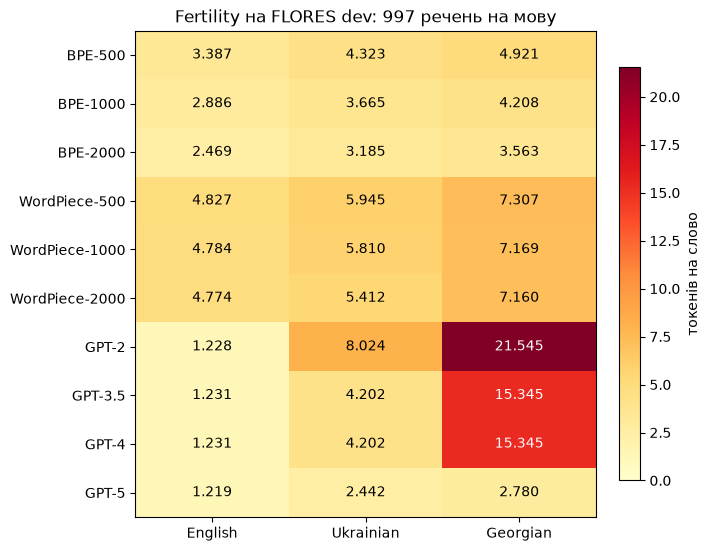

In [15]:
import matplotlib.pyplot as plt
import numpy as np

names = list(results)
languages = list(flores)
values = np.array([[results[name][lang] for lang in languages] for name in names])
fig, ax = plt.subplots(figsize=(7, 5.4), layout="constrained")
image = ax.imshow(values, cmap="YlOrRd", vmin=0, aspect="auto")
ax.set_xticks(range(len(languages)), ["English", "Ukrainian", "Georgian"])
ax.set_yticks(range(len(names)), names)
ax.set_title("Fertility на FLORES dev: 997 речень на мову")
for i in range(len(names)):
    for j in range(len(languages)):
        color = "white" if values[i, j] > values.max() * 0.62 else "black"
        ax.text(j, i, f"{values[i, j]:.3f}", ha="center", va="center", color=color)
fig.colorbar(image, ax=ax, label="токенів на слово", shrink=0.85)
plt.show()

### Змішані приклади

Я перевіряю перемикання мов, числа, email, URL та emoji. Для кожного тексту показую повну кількість токенів і перші 12 елементів списку.

In [16]:
MIXED_CASES = [
    "Я навчаю tokenizer на FLORES dataset.",
    "The model розуміє ქართულ ენას?",
    "Київ -> Tbilisi -> თბილისი -> London 🌍",
    "Замовлення №2026-09-24 коштує $19.99.",
    "support@example.com або https://example.com/допомога",
    "я дуже втомився від курсу основи Large Language Models",
]


def compare_mixed_cases(texts, tokenizers):
    for text in texts:
        print("\nТекст:", text)
        for name, tokenize in tokenizers.items():
            tokens = tokenize(text)
            print(f"  {name:18} {len(tokens):3} токенів; {tokens[:12]}")


compare_mixed_cases(MIXED_CASES, tokenizers_to_compare)


Текст: Я навчаю tokenizer на FLORES dataset.
  BPE-500             24 токенів; ['я</w>', 'на', 'в', 'ча', 'ю</w>', 't', 'o', 'k', 'en', 'i', 'z', 'er</w>']
  BPE-1000            23 токенів; ['я</w>', 'на', 'в', 'ча', 'ю</w>', 'to', 'k', 'en', 'i', 'z', 'er</w>', 'на</w>']
  BPE-2000            19 токенів; ['я</w>', 'нав', 'ча', 'ю</w>', 'to', 'k', 'en', 'iz', 'er</w>', 'на</w>', 'fl', 'or']
  WordPiece-500       32 токенів; ['я', 'н', '##а', '##в', '##ч', '##а', '##ю', 't', '##o', '##k', '##e', '##n']
  WordPiece-1000      32 токенів; ['я', 'н', '##а', '##в', '##ч', '##а', '##ю', 't', '##o', '##k', '##e', '##n']
  WordPiece-2000      32 токенів; ['я', 'н', '##а', '##в', '##ч', '##а', '##ю', 't', '##o', '##k', '##e', '##n']
  GPT-2               21 токенів; [140, 107, 12466, 121, 16142, 38857, 141, 229, 16142, 141, 236, 11241]
  GPT-3.5             13 токенів; [86491, 6850, 18226, 6148, 1506, 12182, 47058, 13373, 435, 1623, 7157, 10550]
  GPT-4               13 токенів; [86491, 6850, 1

## Порівняння методів

| Метод | Перевага | Обмеження |
| --- | --- | --- |
| Слова | Простий і короткий запис знайомих слів | OOV та великий словник словоформ |
| N-грами | Спільні частини нових слів | Перекриття, фіксоване `n`, невідомі фрагменти |
| BPE | Часті фрагменти скорочують вхід | Залежність від корпусу й алфавіту |
| WordPiece | Повторне використання підслів | Greedy та `[UNK]` для всього слова |
| GPT | Готове байтове кодування | Різна ефективність для мов; прив’язка до моделі |

Fertility порівнюю разом із UNK. Власні методи знижують регістр, GPT зберігає текст; навчальні дані й розміри словників теж відрізняються.

## Висновок

Для української при збільшенні словника 500 → 2000 BPE знизив fertility з 4.323 до 3.185, WordPiece - з 5.945 до 5.412. BPE зливає часті пари, тоді як WordPiece-score може вибирати рідкісні фрагменти.

GPT-2 дав 1.228 / 8.024 / 21.545 для англійської / української / грузинської, GPT-5 - 1.219 / 2.442 / 2.780. Різниця пов’язана з покриттям словника, письмом і словоформами. Ці числа описують токенізацію цього корпусу, а не якість відповідей моделей.

Для оцінки нових текстів потрібен окремий тестовий корпус. Низьку fertility перевіряю разом із UNK, бо невідоме слово може бути втрачено.